# 23. Daily-change and acceleration evaluation

Supplementary evaluation of existing full-feature Dynamic Panel predictions, including Pressure. No retraining or feature changes. Trajectory MAE remains primary. Same585 ZIPs ×28 May2020 origins. Daily change is day2−day1 and day3−day2; acceleration is day3−2×day2+day1, WITHIN each same-origin path. Raw daily onset counts, not smoothed counts. Exploratory historical replay, not an untouched test.

In [1]:
from pathlib import Path
import hashlib, json
import numpy as np
import pandas as pd

def evaluate_dynamics(archive, output):
    archive, output = Path(archive), Path(output)
    output.mkdir(parents=True, exist_ok=True)
    with np.load(archive, allow_pickle=False) as z:
        a = z['actual_cases'].copy()
        p = np.maximum(z['raw_predictions'], 0)
        dates = pd.to_datetime(z['forecast_origins'])
        assert np.array_equal(z['horizons'], [1, 2, 3])
        regions = len(z['zip'])
    assert a.shape == p.shape and np.isfinite(a).all() and np.isfinite(p).all()
    # Differences are within each SAME-origin path, never across forecast origins.
    da, dp = np.diff(a, axis=2), np.diff(p, axis=2)
    aa, ap = np.diff(a, n=2, axis=2)[..., 0], np.diff(p, n=2, axis=2)[..., 0]
    de, ae = dp-da, ap-aa
    assert np.allclose(aa, a[...,2]-2*a[...,1]+a[...,0])
    assert np.allclose(de, np.diff(p-a, axis=2))
    assert np.allclose(ae, (p-a)[...,2]-2*(p-a)[...,1]+(p-a)[...,0])
    rows=[]
    def add(name,e,truth,pred,unit):
        rows.append(dict(measure=name,MAE=float(np.abs(e).mean()),RMSE=float(np.sqrt(np.mean(e**2))),mean_bias=float(e.mean()),strict_sign_agreement=float((np.sign(truth)==np.sign(pred)).mean()),actual_zero_share=float((truth==0).mean()),observations=e.size,unit=unit))
    add('daily_change_pooled',de,da,dp,'cases/day')
    for k in range(2): add(f'day{k+1}_to_day{k+2}_change',de[...,k],da[...,k],dp[...,k],'cases/day')
    add('acceleration',ae,aa,ap,'cases/day^2')
    score=pd.DataFrame(rows);score.to_csv(output/'dynamics_scorecard.csv',index=False)
    daily=pd.DataFrame(dict(forecast_origin=dates,change_MAE=np.abs(de).mean(axis=(0,2)),acceleration_MAE=np.abs(ae).mean(axis=0),change_sign_agreement=(np.sign(da)==np.sign(dp)).mean(axis=(0,2)),acceleration_sign_agreement=(np.sign(aa)==np.sign(ap)).mean(axis=0)))
    daily.to_csv(output/'dynamics_by_forecast_origin.csv',index=False)
    labels=['Negative','Zero','Positive']
    cm=np.array([[np.sum((np.sign(aa)==i)&(np.sign(ap)==j)) for j in [-1,0,1]] for i in [-1,0,1]])
    pd.DataFrame(cm,index=pd.Index(labels,name='Actual acceleration'),columns=labels).to_csv(output/'acceleration_confusion_counts.csv')
    rng=np.random.default_rng(20261027);T=len(dates);block=min(7,T)
    starts=rng.integers(0,T-block+1,(2000,int(np.ceil(T/block))))
    draws=(starts[...,None]+np.arange(block)).reshape(2000,-1)[:,:T]
    ci=[]
    for col in daily.columns[1:]:
        lo,hi=np.quantile(daily[col].to_numpy()[draws].mean(axis=1),[.025,.975])
        ci.append(dict(metric=col,ci95_low=lo,ci95_high=hi,block_days=block,resamples=2000))
    pd.DataFrame(ci).to_csv(output/'exploratory_date_block_intervals.csv',index=False)
    groups=[]
    for name,mask in [('all_paths',np.ones(a.shape[:2],bool)),('actual_all_three_zero',(a==0).all(axis=2)),('actual_endpoint_nonflat',a[...,2]!=a[...,0]),('actual_nonzero_acceleration',aa!=0)]:
        groups.append(dict(subgroup=name,paths=int(mask.sum()),change_MAE=float(np.abs(de[mask]).mean()) if mask.any() else None,acceleration_MAE=float(np.abs(ae[mask]).mean()) if mask.any() else None))
    pd.DataFrame(groups).to_csv(output/'dynamics_subgroups.csv',index=False)
    definition=dict(source_sha256=hashlib.sha256(archive.read_bytes()).hexdigest(),regions=regions,origins=T,paths=int(aa.size),change_observations=int(da.size),change='Day2-Day1 and Day3-Day2, within same-origin raw-count path, one-day spacing',acceleration='Day3-2*Day2+Day1; one second difference per path',prediction_processing='max(raw_predictions,0), no rounding; matches Notebook22',sign='Exact negative/zero/positive, no tolerance tuning',primary_metric_unchanged='trajectory_MAE',no_refit=True,scope='Fixed March1-April29 2020 training; May1-28 origins; exploratory retrospective replay',intervals='Pointwise 7-origin moving-block bootstrap, 2000 resamples; all regions resampled together. Only28 origins, conditional on existing model/cohort; not post-selection-adjusted.',interpretation='Difference of daily NEW counts, not cumulative cases. Negative acceleration does not necessarily imply declining cases. No jerk estimate from only3 future points; no outbreak claims.')
    (output/'dynamics_definition.json').write_text(json.dumps(definition,indent=2),encoding='utf8')
    assert cm.sum()==aa.size and np.isclose(score.iloc[0].MAE,daily.change_MAE.mean())
    (output/'verification.json').write_text(json.dumps(dict(no_model_refitted=True,within_path_difference_identities_verified=True,confusion_total_matches_paths=True,daily_and_pooled_MAE_reconcile=True),indent=2))
    report='# Three-day trajectory: change and acceleration diagnostics\n\nNo refitting, feature changes or target changes. Trajectory MAE remains the primary metric. All scores are per-ZIP paths, not changes in the summed state curve.\n\n'+score.to_string(index=False)+'\n\nChange MAE averages two absolute change errors within each path, then all paths. Acceleration MAE averages one absolute second-difference error per path. Bias is predicted minus actual. Units use one-day spacing; these describe changes in DAILY NEW cases. Sign agreement uses exact zeros and is sensitive to class imbalance and small predicted changes. The zero share is the accuracy of an always-zero sign reference, not an alternative fitted model.\n\nThese diagnostics assess numerical changes, not clinical outbreak detection. Second differences can amplify daily-count noise. Subgroups overlap and do not form a partition. Intervals are exploratory and conditional on the existing historical replay. No p-value is calculated because no paired competing-model hypothesis is being tested.\n'
    (output/'RESULTS.md').write_text(report,encoding='utf8')
    try:
        import matplotlib
    except ImportError:
        print('Scores saved. Install matplotlib to generate the optional figure.')
        return score, daily
    matplotlib.use('Agg')
    import matplotlib.pyplot as plt
    fig,ax=plt.subplots(1,2,figsize=(12,4))
    for axis,col,title in zip(ax,['change_MAE','acceleration_MAE'],['Daily-change MAE (cases/day)','Acceleration MAE (cases/day²)']):
        axis.plot(dates,daily[col],color='#2563eb',marker='o',ms=3)
        axis.axhline(daily[col].mean(),color='#087f78',ls='--',label=f'Mean {daily[col].mean():.3f}')
        axis.set(title=title,xlabel='Forecast origin');axis.legend(frameon=False);axis.tick_params(axis='x',rotation=30);axis.grid(alpha=.2)
    fig.suptitle('Dynamic Panel: supplementary trajectory diagnostics | May 2020')
    fig.tight_layout();fig.savefig(output/'dynamics_errors_by_origin.png',dpi=250);plt.close(fig)
    return score, daily


In [2]:
ROOT = Path.cwd()
if not (ROOT / 'fixed60_trajectory_outputs').exists() and (ROOT / 'Weikun').is_dir():
    ROOT = ROOT / 'Weikun'
ARCHIVE = ROOT / 'fixed60_trajectory_outputs' / 'fixed60_20261027' / 'predictions.npz'
OUTPUT = ROOT / 'trajectory_dynamics_outputs' / 'dynamics_20261027'
scorecard, daily_scores = evaluate_dynamics(ARCHIVE, OUTPUT)
display(scorecard)
print('Saved to:', OUTPUT.resolve())

,measure,MAE,RMSE,mean_bias,strict_sign_agreement,actual_zero_share,observations,unit
0,daily_change_pooled,0.794910,1.469735,0.163383,0.307326,0.658578,32760,cases/day
1,day1_to_day2_change,0.792406,1.463628,0.154097,0.302381,0.655128,16380,cases/day
2,day2_to_day3_change,0.797413,1.475816,0.172668,0.312271,0.662027,16380,cases/day
3,acceleration,1.367774,2.475866,0.018572,0.299939,0.558852,16380,cases/day^2


Saved to: C:\Users\41240\OneDrive\文档\GitHub\practicum-project\Weikun\trajectory_dynamics_outputs\dynamics_20261027


,subgroup,paths,change_MAE,acceleration_MAE
0,all_paths,16380,0.794910,1.367774
1,actual_all_three_zero,8631,0.299826,0.579031
2,actual_endpoint_nonflat,5643,1.364041,2.161069
3,actual_nonzero_acceleration,7226,1.371184,2.333261


,Actual acceleration,Negative,Zero,Positive
0,Negative,1457,40,1556
1,Zero,3430,972,4752
2,Positive,1597,92,2484


,metric,ci95_low,ci95_high,block_days,resamples
0,change_MAE,0.740416,0.849380,7,2000
1,acceleration_MAE,1.261570,1.476560,7,2000
2,change_sign_agreement,0.270813,0.350031,7,2000
3,acceleration_sign_agreement,0.255675,0.348840,7,2000


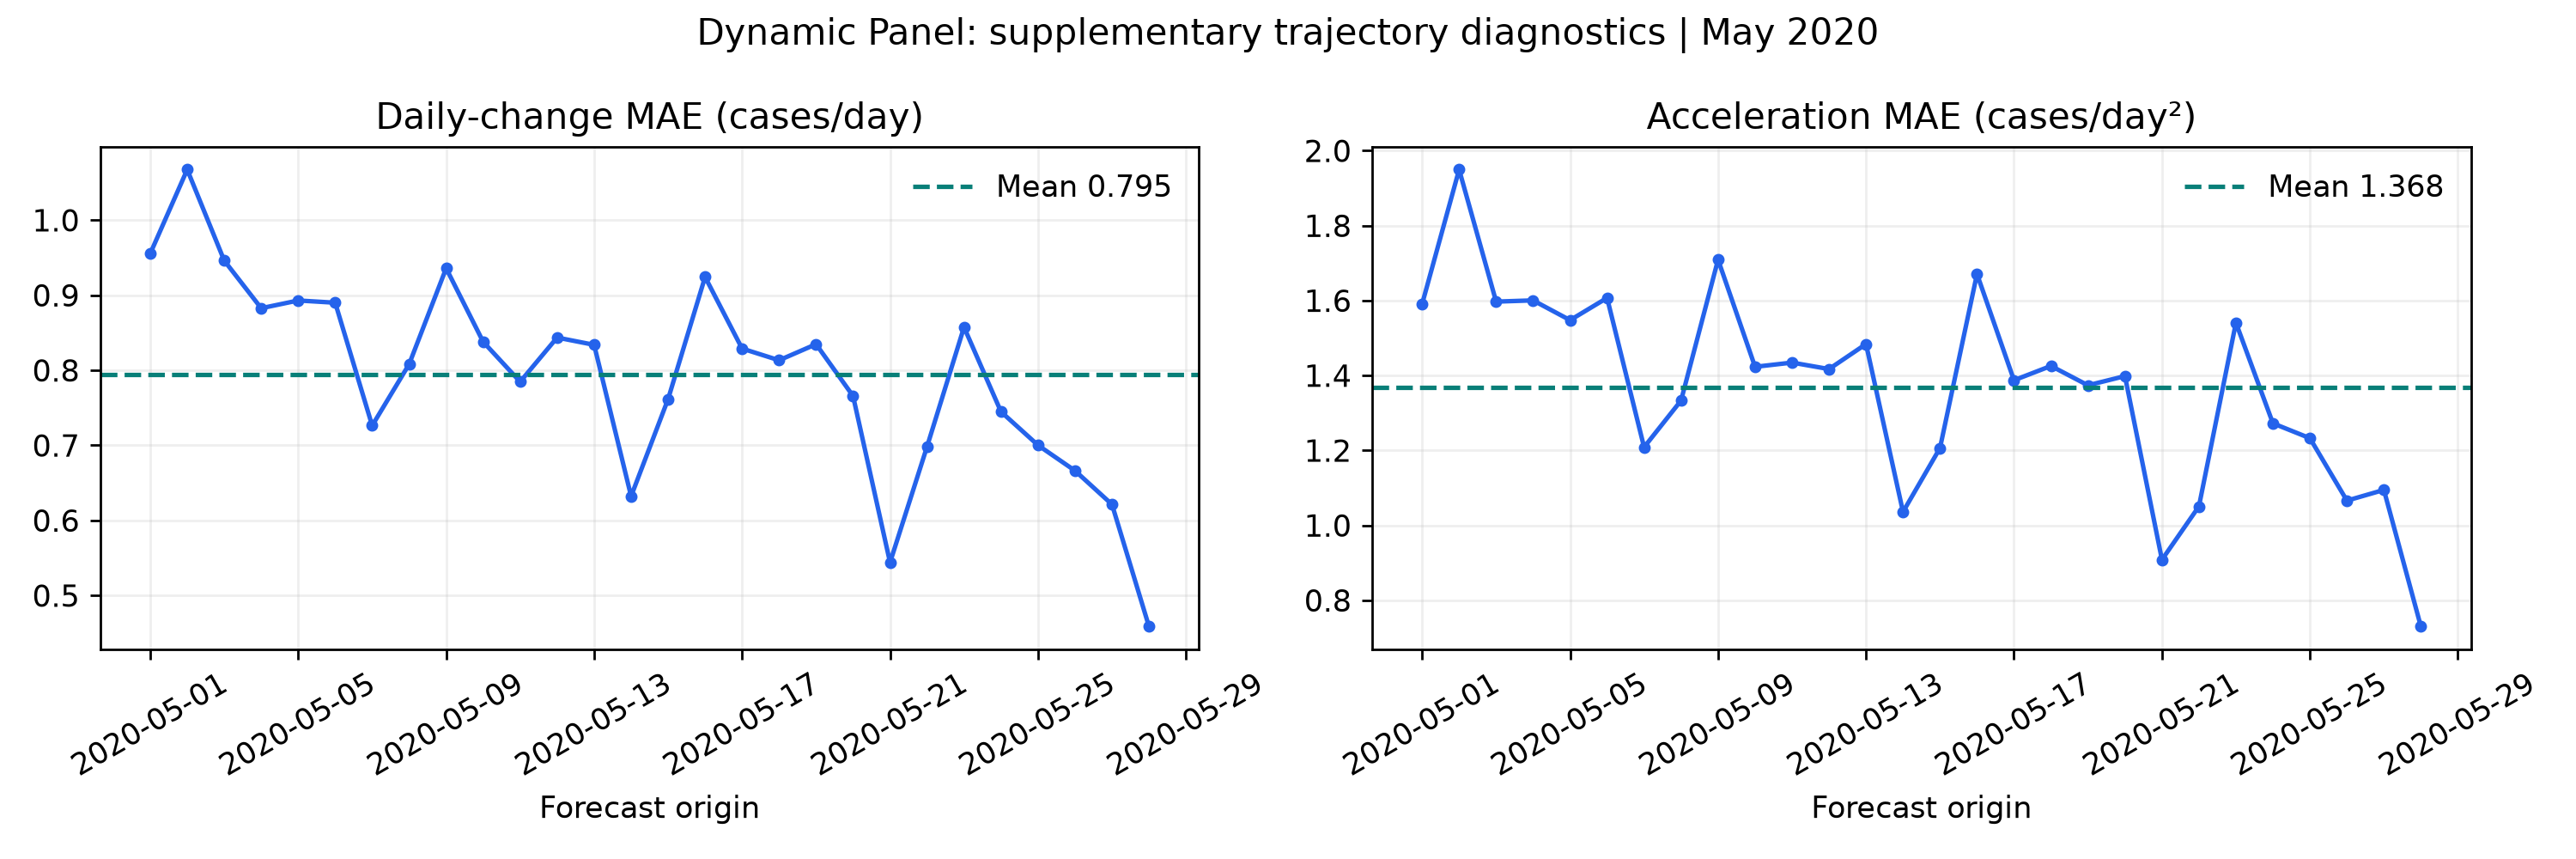

In [3]:
display(pd.read_csv(OUTPUT / 'dynamics_subgroups.csv'))
display(pd.read_csv(OUTPUT / 'acceleration_confusion_counts.csv'))
display(pd.read_csv(OUTPUT / 'exploratory_date_block_intervals.csv'))
from IPython.display import Image, display
if (OUTPUT / 'dynamics_errors_by_origin.png').exists():
    display(Image(filename=str(OUTPUT / 'dynamics_errors_by_origin.png')))

## Interpretation
Lower MAE is better. Bias is predicted minus actual. Sign agreement treats exact zero separately and should be read alongside actual-zero share. Negative acceleration need not mean declining cases. There are32,760 change observations and16,380 accelerations; overlapping paths are not independent. Block intervals are exploratory, conditional on the existing model/cohort and only28 origins. Subgroups overlap. No p-value: no paired competing-model hypothesis is tested. No outbreak-warning claim. All scores aggregate individual ZIP paths, not summed regional curves.